In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

%matplotlib inline

plt.style.use("seaborn-v0_8-whitegrid")
plt.rc("figure", autolayout=True)
plt.rc(
    "axes",
    labelweight="bold",
    labelsize="large",
    titleweight="bold",
    titlesize=14,
    titlepad=10,
)

accidents_data = pd.read_csv("../datasets/fe-course-data/accidents.csv")
autos_data = pd.read_csv("../datasets/fe-course-data/autos.csv")
concrete_data = pd.read_csv("../datasets/fe-course-data/concrete.csv")
customer_data = pd.read_csv("../datasets/fe-course-data/customer.csv")

In [3]:
### Mathematical transforms
autos_data["stroke_ratio"] = autos_data.stroke / autos_data.bore
autos_data[["stroke", "bore", "stroke_ratio"]].head()

,stroke,bore,stroke_ratio
0,2.68,3.47,0.772334
1,2.68,3.47,0.772334
2,3.47,2.68,1.294776
3,3.40,3.19,1.065831
4,3.40,3.19,1.065831


In [6]:
autos_data["displacement"] = (
    np.pi * ((0.5 * autos_data.bore) ** 2) * autos_data.stroke * autos_data.num_of_cylinders
)
autos_data[["stroke", "bore", "stroke_ratio", "displacement"]].head()

,stroke,bore,stroke_ratio,displacement
0,2.68,3.47,0.772334,101.377976
1,2.68,3.47,0.772334,101.377976
2,3.47,2.68,1.294776,117.446531
3,3.40,3.19,1.065831,108.695147
4,3.40,3.19,1.065831,135.868934


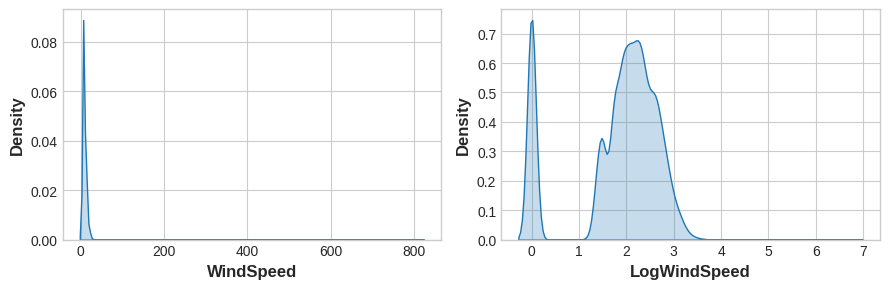

In [12]:
# If the feature has 0.0 values, use np.log1p (log(1+x)) instead of np.log
accidents_data["LogWindSpeed"] = accidents_data.WindSpeed.apply(np.log1p)

# Plot a comparison
fig, axs = plt.subplots(1, 2, figsize=(9, 3))
sns.kdeplot(accidents_data.WindSpeed, fill=True, ax=axs[0])
sns.kdeplot(accidents_data.LogWindSpeed, fill=True, ax=axs[1]);

In [13]:
### Counts
roadway_features = ["Amenity", "Bump", "Crossing", "GiveWay",
    "Junction", "NoExit", "Railway", "Roundabout", "Station", "Stop",
    "TrafficCalming", "TrafficSignal"]
accidents_data["RoadwayFeatures"] = accidents_data[roadway_features].sum(axis=1)

accidents_data[roadway_features + ["RoadwayFeatures"]].head(10)

,Amenity,Bump,Crossing,GiveWay,Junction,NoExit,Railway,Roundabout,Station,Stop,TrafficCalming,TrafficSignal,RoadwayFeatures
0,False,False,False,False,False,False,False,False,False,False,False,False,0
1,False,False,False,False,False,False,False,False,False,False,False,False,0
2,False,False,False,False,False,False,False,False,False,False,False,False,0
3,False,False,False,False,False,False,False,False,False,False,False,False,0
4,False,False,False,False,False,False,False,False,False,False,False,False,0
5,False,False,False,False,True,False,False,False,False,False,False,False,1
6,False,False,False,False,False,False,False,False,False,False,False,False,0
7,False,False,True,False,False,False,False,False,False,False,False,True,2
8,False,False,True,False,False,False,False,False,False,False,False,True,2
9,False,False,False,False,False,False,False,False,False,False,False,False,0


In [15]:
components = [ "Cement", "BlastFurnaceSlag", "FlyAsh", "Water",
               "Superplasticizer", "CoarseAggregate", "FineAggregate"]
concrete_data["Components"] = concrete_data[components].gt(0).sum(axis=1)
concrete_data[components + ["Components"]].head(10)

,Cement,BlastFurnaceSlag,FlyAsh,Water,Superplasticizer,CoarseAggregate,FineAggregate,Components
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,5
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,5
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,5
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,5
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,5
5,266.0,114.0,0.0,228.0,0.0,932.0,670.0,5
6,380.0,95.0,0.0,228.0,0.0,932.0,594.0,5
7,380.0,95.0,0.0,228.0,0.0,932.0,594.0,5
8,266.0,114.0,0.0,228.0,0.0,932.0,670.0,5
9,475.0,0.0,0.0,228.0,0.0,932.0,594.0,4


In [17]:
### Building-Up and Breaking-Down Features
customer_data[["Type", "Level"]] = (  # Create two new features
    customer_data["Policy"]           # from the Policy feature
    .str                              # through the string accessor
    .split(" ", expand=True)          # by splitting on " "    
)                                     # and expanding the result into separate columns

customer_data[["Policy", "Type", "Level"]].head(10)

,Policy,Type,Level
0,Corporate L3,Corporate,L3
1,Personal L3,Personal,L3
2,Personal L3,Personal,L3
3,Corporate L2,Corporate,L2
4,Personal L1,Personal,L1
5,Personal L3,Personal,L3
6,Corporate L3,Corporate,L3
7,Corporate L3,Corporate,L3
8,Corporate L3,Corporate,L3
9,Special L2,Special,L2


In [18]:
autos_data["make_and_style"] = autos_data["make"] + "_" + autos_data["body_style"]
autos_data[["make", "body_style", "make_and_style"]].head()

,make,body_style,make_and_style
0,alfa-romero,convertible,alfa-romero_convertible
1,alfa-romero,convertible,alfa-romero_convertible
2,alfa-romero,hatchback,alfa-romero_hatchback
3,audi,sedan,audi_sedan
4,audi,sedan,audi_sedan


In [21]:
### Group transforms
customer_data["AverageIncome"] = (
    customer_data.groupby("State")  # for each state
    ["Income"]                      # select the income
    .transform("mean")              # and compute its mean
)

customer_data[["State", "Income", "AverageIncome"]].head(10)

,State,Income,AverageIncome
0,Washington,56274,38122.733083
1,Arizona,0,37405.402231
2,Nevada,48767,38369.605442
3,California,0,37558.946667
4,Washington,43836,38122.733083
5,Oregon,62902,37557.283353
6,Oregon,55350,37557.283353
7,Arizona,0,37405.402231
8,Oregon,14072,37557.283353
9,Oregon,28812,37557.283353


In [22]:
customer_data["StateFreq"] = (
    customer_data.groupby("State")["State"].transform("count")
    / customer_data.State.count()
)

customer_data[["State", "StateFreq"]].head(10)

,State,StateFreq
0,Washington,0.087366
1,Arizona,0.186446
2,Nevada,0.096562
3,California,0.344865
4,Washington,0.087366
5,Oregon,0.284760
6,Oregon,0.284760
7,Arizona,0.186446
8,Oregon,0.284760
9,Oregon,0.284760


In [24]:
# Create splits
df_train = customer_data.sample(frac=0.5)
df_valid = customer_data.drop(df_train.index)

# Create the average claim amount by coverage type, on the training set
df_train["AverageClaim"] = df_train.groupby("Coverage")["ClaimAmount"].transform("mean")

# Merge the values into the validation set
df_valid = df_valid.merge(
    df_train[["Coverage", "AverageClaim"]].drop_duplicates(),
    on="Coverage",
    how="left",
)

df_valid[["Coverage", "AverageClaim"]].head(10)

,Coverage,AverageClaim
0,Basic,381.14512
1,Premium,670.48601
2,Basic,381.14512
3,Basic,381.14512
4,Premium,670.48601
5,Basic,381.14512
6,Basic,381.14512
7,Basic,381.14512
8,Basic,381.14512
9,Basic,381.14512
